# 02 · Evaluation, visualisation and interpretability (Sachin)

Phase 1 (classical ML) results for Next Day Wildfire Spread (Huot et al., 2022).

**Inputs** (made by teammates' scripts, not by this notebook):
- `reports/preds/{model}.npz`: `y_true` and `y_prob`, each of shape (1689, 64, 64), one map per test patch,
  in the same order as `load_split("test")`. Labels are 1 = fire, 0 = no fire, -1 = unknown.
- `reports/results.csv`: test metrics per model from `src/evaluate.py`. `threshold` was chosen on the **eval** split.
- `reports/best_params.json`: hyperparameters of the tuned XGBoost / LightGBM.

**Rule used everywhere:** pixels with label -1 are dropped before any metric or plot.

**Outputs:** `reports/figures/eval_*.png` and `reports/results_table.md`.

In [1]:
import os
from pathlib import Path

# The notebook lives in notebooks/; move to the repo root so `src` imports and relative paths work.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve

SEED = 0
PREDS = Path("reports/preds")
FIGS = Path("reports/figures")
FIGS.mkdir(parents=True, exist_ok=True)

# Model name in files -> label shown in plots. Order = baselines first, tuned models last.
MODELS = {
    "persistence": "Persistence",
    "logreg_raw": "Logistic reg. (raw)",
    "rf_raw": "Random forest (raw)",
    "xgb_raw": "XGBoost (raw)",
    "xgboost": "XGBoost (tuned, all features)",
    "lightgbm": "LightGBM (tuned, all features)",
}
# Fixed colour per model (colour-blind-checked palette), dashed = baseline, solid = our tuned models.
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#6250d6"]))
STYLE = {m: "-" if m in ("xgboost", "lightgbm") else "--" for m in MODELS}

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

results = pd.read_csv("reports/results.csv").set_index("model")
results

,pr_auc,roc_auc,precision,recall,f1,threshold,best_f1,best_f1_threshold,recall_at_1fpr,recall_at_5fpr,n_pixels,fire_rate
model,,,,,,,,,,,,
persistence,0.1065,0.6333,0.3572,0.2728,0.3093,0.5000,0.3093,1.0000,0.2728,0.2728,6727699,0.0125
logreg_raw,0.1457,0.7985,0.3776,0.2658,0.3120,0.9358,0.3128,0.9262,0.2813,0.3190,6727699,0.0125
rf_raw,0.1565,0.8163,0.3712,0.2699,0.3125,0.8474,0.3141,0.8804,0.2785,0.3622,6727699,0.0125
xgb_raw,0.1455,0.7955,0.3373,0.2570,0.2917,0.8744,0.2962,0.9053,0.2666,0.3752,6727699,0.0125
xgboost,0.2559,0.9032,0.2570,0.5045,0.3405,0.9237,0.3587,0.9544,0.3904,0.6748,6727699,0.0125
lightgbm,0.2519,0.8959,0.2527,0.5143,0.3389,0.9158,0.3584,0.9500,0.3893,0.6696,6727699,0.0125


In [2]:
def load_preds(name):
    """Return y_true and y_prob maps (1689, 64, 64) for one model."""
    d = np.load(PREDS / f"{name}.npz")
    return d["y_true"], d["y_prob"]


# All models were scored on the same test pixels, so we read the labels once.
y_map, _ = load_preds("xgboost")
labelled = y_map != -1                      # mask of pixels we are allowed to score
y_flat = y_map[labelled].astype(int)        # 1-D vector of 0/1 labels
probs = {m: load_preds(m)[1][labelled] for m in MODELS}   # 1-D probabilities, same order as y_flat

fire_rate = y_flat.mean()
print(f"test pixels: {y_map.size:,} | labelled: {labelled.sum():,} | dropped (-1): {(~labelled).sum():,}")
print(f"next-day fire rate among labelled pixels: {fire_rate:.4f}  (about 1 fire pixel in {1 / fire_rate:.0f})")

test pixels: 6,918,144 | labelled: 6,727,699 | dropped (-1): 190,445
next-day fire rate among labelled pixels: 0.0125  (about 1 fire pixel in 80)


## 1 · Precision-recall and ROC curves (test split)

**Why PR first.** Only 1.25% of labelled test pixels burn. ROC uses the false positive rate FP / (all no-fire pixels);
with 79 no-fire pixels per fire pixel, a model can raise many false alarms while FPR stays small, so ROC AUC looks good.
Precision = TP / (TP + FP) is hit directly by those false alarms, so PR AUC is the main metric here
(as in Huot et al. 2022). A random model gets PR AUC ≈ fire rate (0.0125) but ROC AUC = 0.5.

PR AUC is computed as average precision (`average_precision_score`), the same number as in `results.csv`.
The dot on each PR curve is the operating point at the threshold chosen on the **eval** split (best eval F1),
i.e. what the model would actually do on unseen data.

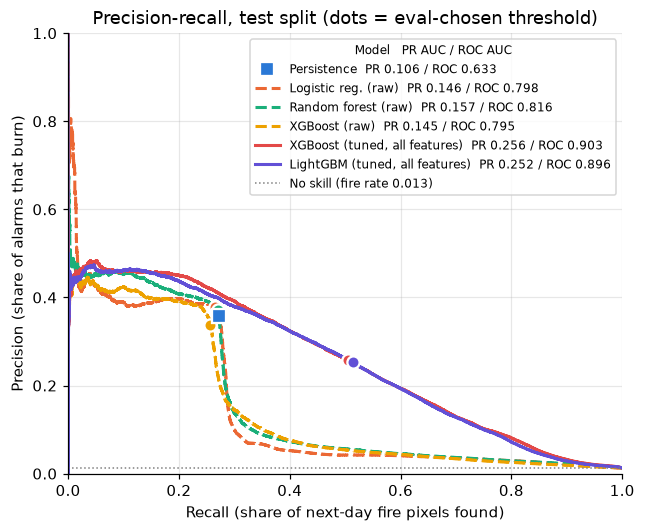

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for m, label in MODELS.items():
    r = results.loc[m]
    legend = f"{label}  PR {r.pr_auc:.3f} / ROC {r.roc_auc:.3f}"
    if m == "persistence":
        # Persistence outputs only 0 or 1, so it has ONE operating point, not a curve
        # (a straight line between PR points would overstate it).
        ax.plot(r.recall, r.precision, "s", ms=9, color=COLORS[m], mec="white", mew=1.5, zorder=6, label=legend)
        continue
    precision, recall, _ = precision_recall_curve(y_flat, probs[m])
    ax.plot(recall, precision, STYLE[m], color=COLORS[m], lw=2, label=legend)
    # Operating point at the eval-chosen threshold (precision/recall columns of results.csv).
    ax.plot(r.recall, r.precision, "o", ms=8, color=COLORS[m], mec="white", mew=1.5, zorder=5)

ax.axhline(fire_rate, color="grey", lw=1, ls=":", label=f"No skill (fire rate {fire_rate:.3f})")
ax.set(xlabel="Recall (share of next-day fire pixels found)", ylabel="Precision (share of alarms that burn)",
       xlim=(0, 1), ylim=(0, 1), title="Precision-recall, test split (dots = eval-chosen threshold)")
ax.legend(fontsize=8, loc="upper right", title="Model   PR AUC / ROC AUC", title_fontsize=8)
fig.savefig(FIGS / "eval_pr_curves.png")
plt.show()

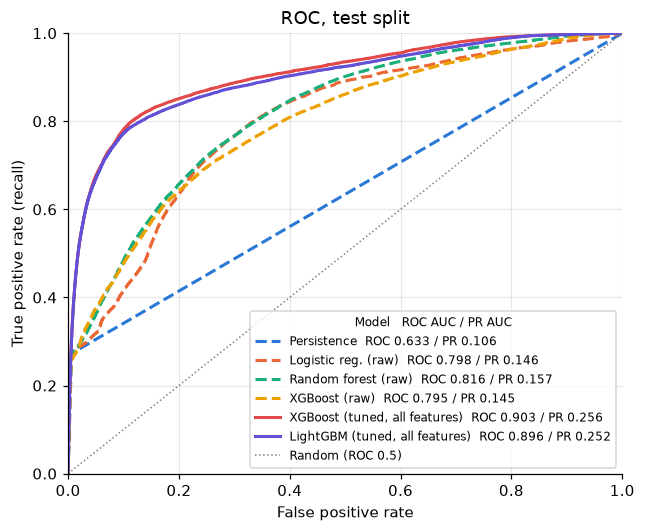

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 5.2))
for m, label in MODELS.items():
    fpr, tpr, _ = roc_curve(y_flat, probs[m])
    r = results.loc[m]
    ax.plot(fpr, tpr, STYLE[m], color=COLORS[m], lw=2, label=f"{label}  ROC {r.roc_auc:.3f} / PR {r.pr_auc:.3f}")

ax.plot([0, 1], [0, 1], color="grey", lw=1, ls=":", label="Random (ROC 0.5)")
ax.set(xlabel="False positive rate", ylabel="True positive rate (recall)", xlim=(0, 1), ylim=(0, 1),
       title="ROC, test split")
ax.legend(fontsize=8, loc="lower right", title="Model   ROC AUC / PR AUC", title_fontsize=8)
fig.savefig(FIGS / "eval_roc_curves.png")
plt.show()

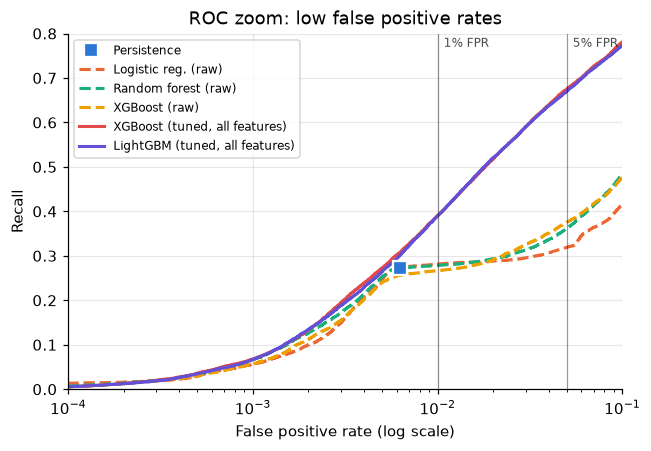

In [5]:
# The low-FPR end is where a fire agency would operate, so zoom in on FPR <= 10% (log x-axis).
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for m, label in MODELS.items():
    fpr, tpr, _ = roc_curve(y_flat, probs[m])
    if m == "persistence":  # single operating point (see PR plot)
        ax.plot(fpr[1], tpr[1], "s", ms=9, color=COLORS[m], mec="white", mew=1.5, zorder=6, label=label)
        continue
    keep = fpr > 0  # log axis cannot show FPR = 0
    ax.plot(fpr[keep], tpr[keep], STYLE[m], color=COLORS[m], lw=2, label=label)
for x in (0.01, 0.05):  # the two fixed false positive rates reported in the results table
    ax.axvline(x, color="black", lw=0.8, alpha=0.4)
    ax.text(x * 1.08, 0.77, f"{x:.0%} FPR", fontsize=8, alpha=0.7)
ax.set(xscale="log", xlim=(1e-4, 0.1), ylim=(0, 0.8), xlabel="False positive rate (log scale)",
       ylabel="Recall", title="ROC zoom: low false positive rates")
ax.legend(fontsize=8, loc="upper left")
fig.savefig(FIGS / "eval_roc_lowfpr.png")
plt.show()

**Reading the curves**
- The two tuned models (solid) are clearly above every baseline across the whole PR curve:
  PR AUC 0.256 (XGBoost) and 0.252 (LightGBM) against 0.146-0.157 for models trained on the 12 raw channels.
  Engineered fire-neighbourhood features account for most of this gap (see Task 4).
- XGBoost and LightGBM are almost on top of each other, so the choice of boosting library matters far less than the features.
- Persistence is a single point (square; it outputs only 0 or 1): it finds 27% of next-day fire at 36% precision
  with a false positive rate of only 0.6%.
- The raw-channel baselines collapse right after recall ≈ 0.27: they rank pixels already burning on day t first
  ("fire stays where it is") and have almost no signal for new fire, so their precision drops to ~5%.
  Their eval-chosen operating points sit on top of persistence. The tuned models keep ≈0.25-0.45 precision up to recall 0.5,
  i.e. they also find *new* fire pixels near the front.
- Low-FPR zoom: at persistence's own false positive rate (0.62%) tuned XGBoost finds 31% of fire pixels vs 27%;
  at 1% / 5% FPR it finds 39% / 67%, while persistence stays at 27% (it has no other operating point).
- The eval-chosen threshold of the tuned models sits at higher recall (≈0.50) and lower precision (≈0.26) than the baselines,
  which is where their F1 is highest.
- ROC AUC is 0.80-0.90 for every learned model while PR AUC stays below 0.26. This is the class-imbalance effect explained above.

## 2 · Results table

Built from `reports/results.csv` and written to `reports/results_table.md`.
Precision, recall and F1 are at the threshold chosen on the **eval** split (not tuned on test).
Recall @ 1% / 5% FPR = share of fire pixels found when we allow 1% / 5% of no-fire pixels to be false alarms.

The paper rows are PR AUC from Huot et al. (2022) for reference only. They are not a like-for-like comparison:
their logistic regression and random forest also get the 8 neighbouring pixels of every channel as input,
and their numbers come from their own pipeline. The CNN is a convolutional autoencoder that sees the whole 64×64 patch.

In [6]:
COLUMNS = {  # results.csv column -> table header
    "pr_auc": "PR AUC", "roc_auc": "ROC AUC", "precision": "Precision", "recall": "Recall", "f1": "F1",
    "recall_at_1fpr": "Recall @ 1% FPR", "recall_at_5fpr": "Recall @ 5% FPR",
}
table = results.loc[list(MODELS), list(COLUMNS)].rename(columns=COLUMNS)
table.index = [MODELS[m] for m in table.index]
table.index.name = "Model"

# PR AUC reported by Huot et al. (2022); their LR / RF also use the 8 neighbouring pixels.
PAPER = {"Persistence": 0.115, "Logistic regression (+ 8 neighbours)": 0.198,
         "Random forest (+ 8 neighbours)": 0.225, "CNN autoencoder": 0.284}


def to_markdown(df, best_col_max=True):
    """Small markdown writer (avoids an extra dependency). Bold = best value in each column."""
    lines = ["| " + " | ".join([df.index.name] + list(df.columns)) + " |",
             "|" + "---|" + "---:|" * len(df.columns)]
    best = df.max() if best_col_max else None
    for name, row in df.iterrows():
        cells = [f"**{v:.3f}**" if v == best[c] else f"{v:.3f}" for c, v in row.items()]
        lines.append("| " + " | ".join([name] + cells) + " |")
    return "\n".join(lines)


md_text = "\n".join([
    "# Phase 1 results (test split, 1,689 patches, 6.73M labelled pixels, 1.25% fire)",
    "",
    "Precision / recall / F1 at the decision threshold chosen on the eval split. Bold = best per column.",
    "",
    to_markdown(table),
    "",
    "## Reference: Huot et al. (2022), PR AUC on the same test split",
    "",
    "| Model | PR AUC |",
    "|---|---:|",
    *[f"| {k} | {v:.3f} |" for k, v in PAPER.items()],
    "",
    "Paper LR / RF also use the 8 neighbouring pixels of every channel; numbers are from their pipeline, "
    "so they are a reference point, not a like-for-like comparison.",
    "",
])
Path("reports/results_table.md").write_text(md_text)
print(md_text)

# Phase 1 results (test split, 1,689 patches, 6.73M labelled pixels, 1.25% fire)

Precision / recall / F1 at the decision threshold chosen on the eval split. Bold = best per column.

| Model | PR AUC | ROC AUC | Precision | Recall | F1 | Recall @ 1% FPR | Recall @ 5% FPR |
|---|---:|---:|---:|---:|---:|---:|---:|
| Persistence | 0.106 | 0.633 | 0.357 | 0.273 | 0.309 | 0.273 | 0.273 |
| Logistic reg. (raw) | 0.146 | 0.798 | **0.378** | 0.266 | 0.312 | 0.281 | 0.319 |
| Random forest (raw) | 0.157 | 0.816 | 0.371 | 0.270 | 0.312 | 0.279 | 0.362 |
| XGBoost (raw) | 0.145 | 0.795 | 0.337 | 0.257 | 0.292 | 0.267 | 0.375 |
| XGBoost (tuned, all features) | **0.256** | **0.903** | 0.257 | 0.504 | **0.341** | **0.390** | **0.675** |
| LightGBM (tuned, all features) | 0.252 | 0.896 | 0.253 | **0.514** | 0.339 | 0.389 | 0.670 |

## Reference: Huot et al. (2022), PR AUC on the same test split

| Model | PR AUC |
|---|---:|
| Persistence | 0.115 |
| Logistic regression (+ 8 neighbours) | 0.198 |
|

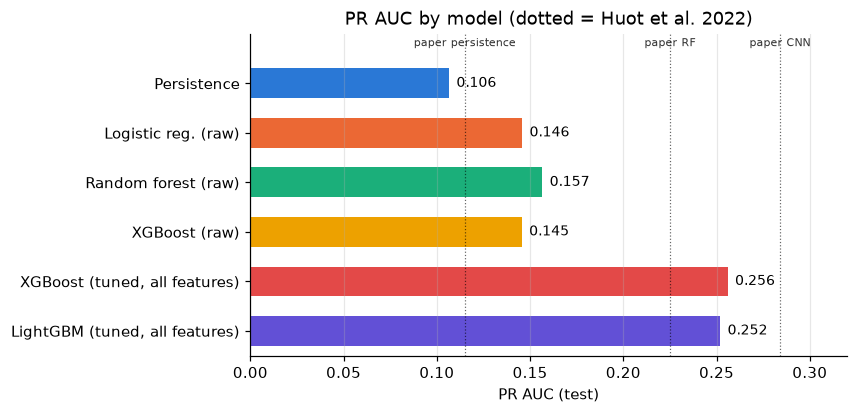

In [7]:
# Same table as a quick bar chart of the two threshold-free metrics plus the paper's PR AUC (for slides).
fig, ax = plt.subplots(figsize=(7, 3.8))
names = list(MODELS)
y = np.arange(len(names))
ax.barh(y, results.loc[names, "pr_auc"], color=[COLORS[m] for m in names], height=0.6)
for i, m in enumerate(names):
    ax.text(results.loc[m, "pr_auc"] + 0.004, i, f"{results.loc[m, 'pr_auc']:.3f}", va="center", fontsize=9)
for v, lab in [(0.115, "paper persistence"), (0.225, "paper RF"), (0.284, "paper CNN")]:
    ax.axvline(v, color="black", lw=0.8, ls=":", alpha=0.6)
    ax.text(v, -0.75, lab, fontsize=7.5, ha="center", alpha=0.8)
ax.set_yticks(y, [MODELS[m] for m in names])
ax.set_ylim(len(names) - 0.5, -1.0)  # top-to-bottom order, with room above the bars for the paper labels
ax.set(xlabel="PR AUC (test)", xlim=(0, 0.32), title="PR AUC by model (dotted = Huot et al. 2022)")
ax.grid(axis="y", visible=False)
fig.savefig(FIGS / "eval_pr_auc_bars.png")
plt.show()

**Reading the table**
- Tuned XGBoost is best on every threshold-free metric (PR AUC 0.256, ROC AUC 0.903, recall 39% @ 1% FPR, 67% @ 5% FPR).
  LightGBM is within 0.004 PR AUC, i.e. a tie.
- At the eval-chosen threshold the tuned models trade precision for recall: they find about 50% of next-day fire
  (vs 26-27% for the baselines) at 25-26% precision, giving the best F1 (0.34).
- The raw baselines do no better than persistence on F1 (0.29-0.31 vs 0.31) even though their PR AUC is higher:
  the extra ranking quality is all at recall levels persistence cannot reach.
- Against the paper: our persistence (0.106) is close to theirs (0.115). Our tuned XGBoost (0.256) is above their
  neighbour-feature random forest (0.225) but below their CNN (0.284): engineered features close most of the gap,
  and the remaining gap is the spatial context the Phase 2 CNN / U-Net is meant to capture.
- `best_f1` in results.csv (0.359 for XGBoost) is the F1 if the threshold were tuned on test; the gap to 0.341
  shows the eval-chosen threshold transfers well.

## 3 · Probability maps (tuned XGBoost, test patches)

Ten test patches are drawn at random (seed 0) from the patches that have at least one fire pixel on day t+1.
For each patch, four panels:
1. **Fire on day t** (`PrevFireMask`, a model input)
2. **True fire on day t+1** (`FireMask`, the label)
3. **XGBoost probability** of fire on day t+1; the arrow shows where the wind blows **to** (patch-mean wind)
4. **XGBoost thresholded** at the eval-chosen threshold, coloured by outcome:
   true positive, false positive (false alarm), false negative (missed fire)

Grey = label -1 (unknown, e.g. cloud). Patches are north-up, 64 × 64 km.

test patches: 1689, exact duplicates: 40
XGBoost eval-chosen threshold: 0.9237
1487 of 1689 test patches have next-day fire; chosen: [33, 69, 120, 290, 443, 515, 856, 1071, 1369, 1432]


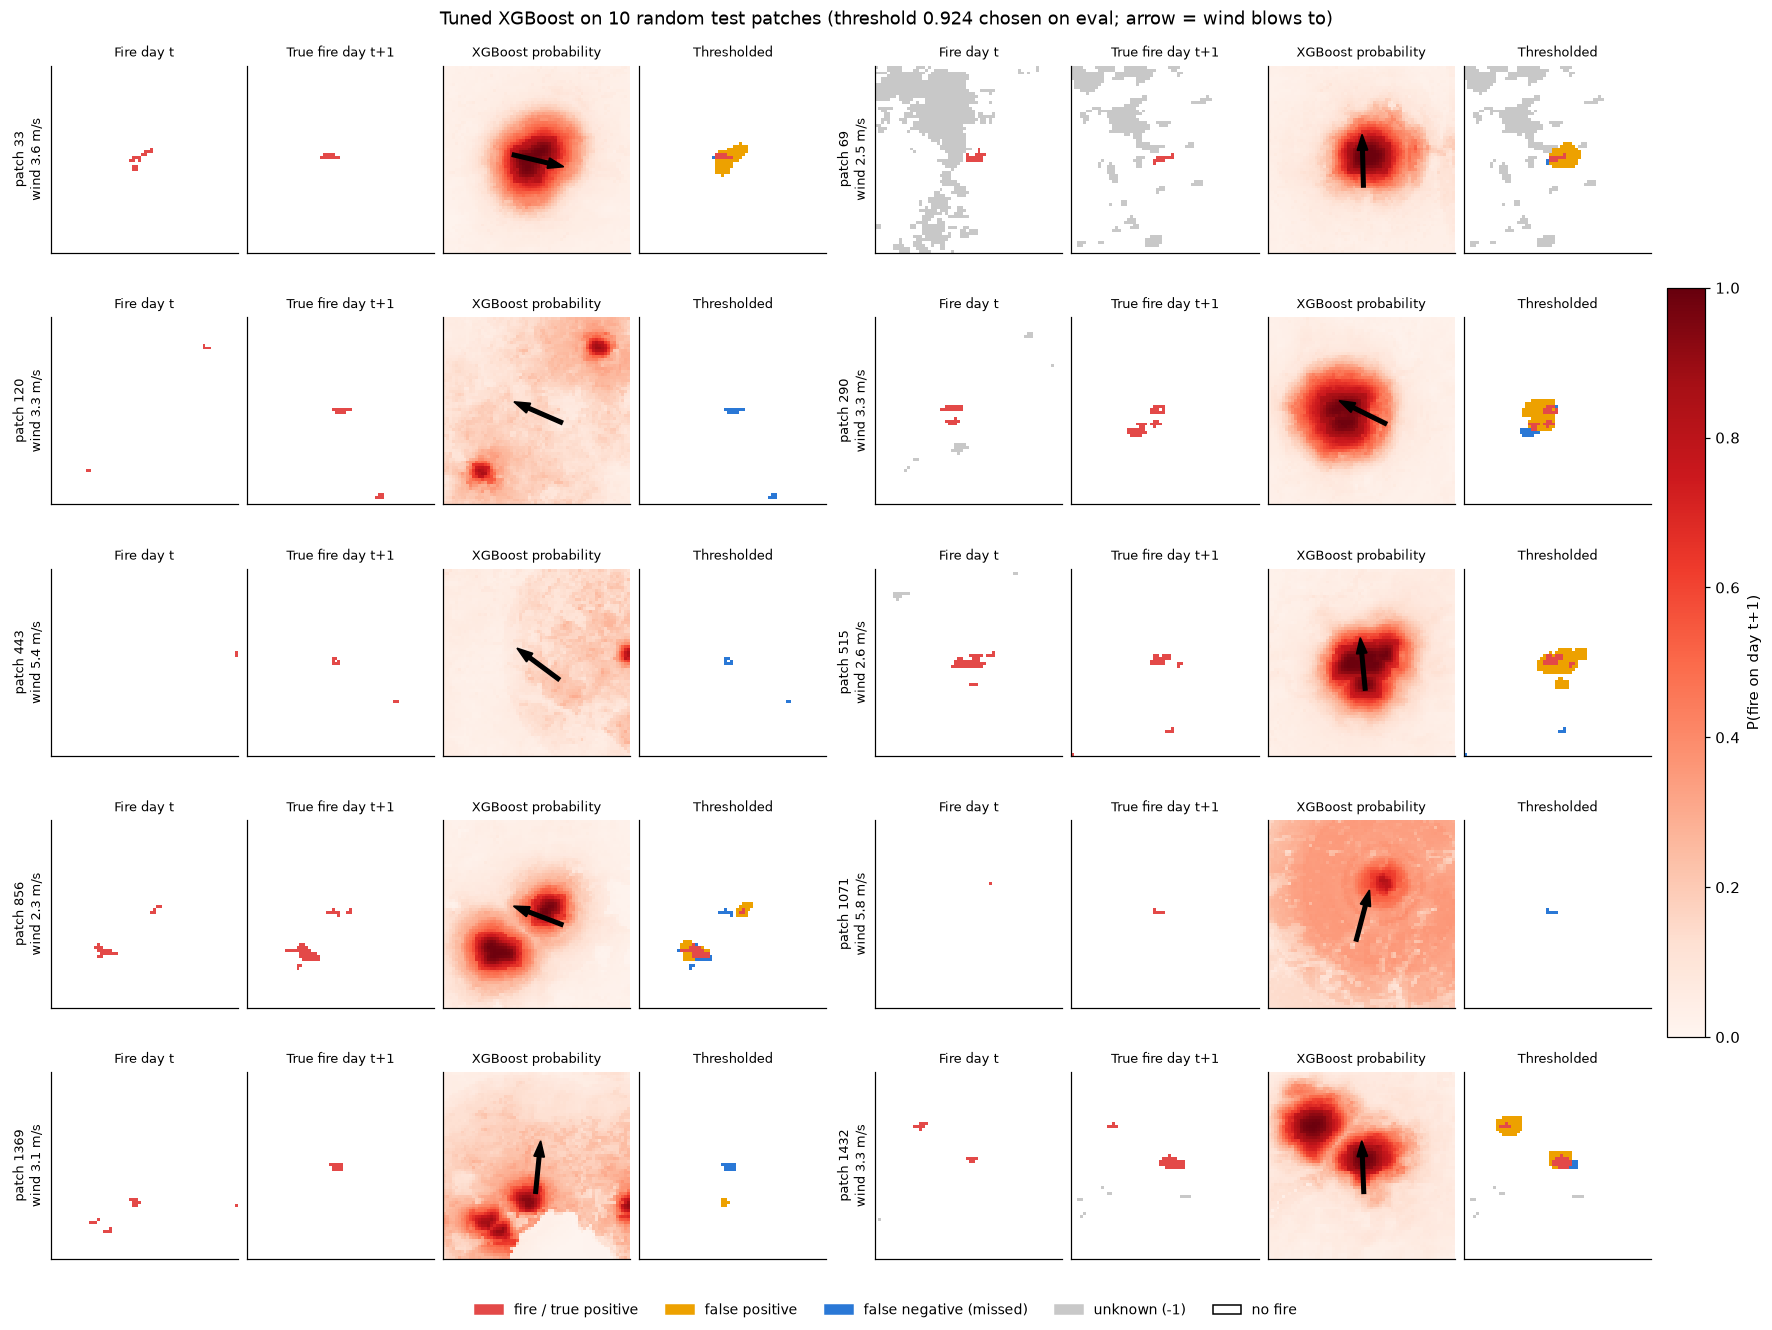

In [8]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from src.data import CHANNELS, load_split

# Day-t inputs we need for plotting: fire mask, wind direction and wind speed.
X_test, y_test = load_split("test")
assert (y_test == y_map).all(), "preds must be in load_split('test') order"
prev_map = X_test[:, CHANNELS.index("PrevFireMask")]
th_map = X_test[:, CHANNELS.index("th")] % 360   # wind comes FROM this direction, deg clockwise from north
vs_map = np.clip(X_test[:, CHANNELS.index("vs")], 0, None)   # wind speed, m/s
elev_map = X_test[:, CHANNELS.index("elevation")]             # used in Task 5 to spot crops of the same place
# The dataset has repeated patches; count exact copies (all 12 channels + label identical).
n_unique = len({X_test[i].tobytes() + y_test[i].tobytes() for i in range(len(X_test))})
print(f"test patches: {len(X_test)}, exact duplicates: {len(X_test) - n_unique}")
del X_test, y_test   # free ~350 MB

p_xgb = load_preds("xgboost")[1]               # (1689, 64, 64) probabilities
THR = results.loc["xgboost", "threshold"]      # chosen on eval
pred_xgb = p_xgb >= THR
print(f"XGBoost eval-chosen threshold: {THR:.4f}")

# Colours: grey unknown, white no fire, red fire. Outcome map: + TP red, FP orange, FN blue.
GREY, FIRE, FP_C, FN_C = "#c8c8c8", "#e34948", "#eda100", "#2a78d6"
MASK_CMAP = ListedColormap([GREY, "white", FIRE])               # values -1, 0, 1 shifted to 0, 1, 2
OUT_CMAP = ListedColormap([GREY, "white", FIRE, FP_C, FN_C])    # 0 unknown, 1 TN, 2 TP, 3 FP, 4 FN


def outcome_map(i):
    """Per-pixel outcome of the thresholded prediction for patch i (codes as in OUT_CMAP)."""
    y, p = y_map[i], pred_xgb[i]
    out = np.ones(y.shape, int)                 # true negative
    out[(y == 1) & p] = 2                       # true positive
    out[(y == 0) & p] = 3                       # false positive
    out[(y == 1) & ~p] = 4                      # false negative
    out[y == -1] = 0                            # unknown label
    return out


def wind_arrow(ax, i):
    """Arrow from the patch centre toward where the wind blows (opposite of th)."""
    th = np.deg2rad(th_map[i])
    mean_th = np.arctan2(np.sin(th).mean(), np.cos(th).mean())   # circular mean of the wind direction
    # downwind step in image coordinates: column = east, row = south
    dx, dy = -np.sin(mean_th), np.cos(mean_th)
    ax.arrow(32 - 9 * dx, 32 - 9 * dy, 18 * dx, 18 * dy, width=1.2, color="black", length_includes_head=True)


def plot_patches(idx, path, title):
    """Two patches per row, four panels per patch: day t | day t+1 | probability | thresholded."""
    n_rows = int(np.ceil(len(idx) / 2))
    fig, axes = plt.subplots(n_rows, 8, figsize=(16, 2.2 * n_rows + 1.0), squeeze=False, layout="constrained")
    heads = ["Fire day t", "True fire day t+1", "XGBoost probability", "Thresholded"]
    for k, ax in enumerate(axes.flat):
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if k // 4 >= len(idx):
            ax.axis("off")
    for n, i in enumerate(idx):
        a = axes[n // 2, 4 * (n % 2): 4 * (n % 2) + 4]
        a[0].imshow(prev_map[i] + 1, cmap=MASK_CMAP, vmin=0, vmax=2, interpolation="nearest")
        a[1].imshow(y_map[i] + 1, cmap=MASK_CMAP, vmin=0, vmax=2, interpolation="nearest")
        im = a[2].imshow(p_xgb[i], cmap="Reds", vmin=0, vmax=1, interpolation="nearest")
        wind_arrow(a[2], i)
        a[3].imshow(outcome_map(i), cmap=OUT_CMAP, vmin=0, vmax=4, interpolation="nearest")
        for h, ax in zip(heads, a):
            ax.set_title(h, fontsize=8.5)
        a[0].set_ylabel(f"patch {i}\nwind {vs_map[i].mean():.1f} m/s", fontsize=8.5)
    fig.suptitle(title, fontsize=12)
    handles = [Patch(color=FIRE, label="fire / true positive"), Patch(color=FP_C, label="false positive"),
               Patch(color=FN_C, label="false negative (missed)"), Patch(color=GREY, label="unknown (-1)"),
               Patch(facecolor="white", edgecolor="black", label="no fire")]
    fig.legend(handles=handles, loc="outside lower center", ncol=5, fontsize=9, frameon=False)
    fig.colorbar(im, ax=axes, shrink=0.6, pad=0.01, label="P(fire on day t+1)")
    fig.savefig(path)
    plt.show()


rng = np.random.default_rng(SEED)
fire_patches = np.flatnonzero((y_map == 1).any(axis=(1, 2)))   # patches with next-day fire
chosen = np.sort(rng.choice(fire_patches, size=10, replace=False))
print(f"{len(fire_patches)} of {len(y_map)} test patches have next-day fire; chosen: {chosen.tolist()}")
plot_patches(chosen, FIGS / "eval_prob_maps.png",
             f"Tuned XGBoost on 10 random test patches (threshold {THR:.3f} chosen on eval; arrow = wind blows to)")

In [9]:
# Per-patch numbers for the 10 maps above (pixels with label -1 excluded).
def patch_stats(idx):
    rows = []
    for i in idx:
        y, lab = y_map[i], y_map[i] != -1
        rows.append({
            "patch": i,
            "fire_t": int((prev_map[i] == 1).sum()),
            "fire_t+1": int((y == 1).sum()),
            "TP": int(((y == 1) & pred_xgb[i]).sum()),
            "FP": int(((y == 0) & pred_xgb[i]).sum()),
            "FN": int(((y == 1) & ~pred_xgb[i]).sum()),
            "unknown_t+1": int((~lab).sum()),
            "wind_m/s": round(float(vs_map[i].mean()), 1),
        })
    return pd.DataFrame(rows).set_index("patch")


patch_stats(chosen)

,fire_t,fire_t+1,TP,FP,FN,unknown_t+1,wind_m/s
patch,,,,,,,
33,16,11,10,63,1,0,3.6
69,19,12,10,67,2,443,2.5
120,6,16,0,0,16,0,3.3
290,23,43,27,78,16,0,3.3
443,2,9,0,0,9,0,5.4
515,48,29,24,110,5,0,2.6
856,22,47,28,42,19,0,2.3
1071,1,5,0,0,5,0,5.8
1369,17,13,0,7,13,0,3.1


**What the maps show**
- The probability map is a smooth halo around the day-t fire that fades over roughly 2-5 km.
  Its shape follows the day-t fire mask, not the wind arrow (e.g. patches 33, 290, 515 are almost round).
  This matches the feature importance in Task 4: distance to the nearest fire drives the model.
- After thresholding, the prediction is close to "day-t fire grown by about 2 km": it catches fire that stays
  or creeps outward (patches 290, 856, 1432) and paints a false-positive ring around small fires that die down (33, 69, 515).
- Fire that appears away from the day-t fire is missed completely (120, 443, 1071, 1369): every next-day fire pixel in
  120, 443 and 1071 is a false negative.
- Patch 69 shows why -1 pixels must be masked: cloud hides much of the patch on day t and day t+1.
- The probabilities are **not calibrated**: training used a 1:5 subsampled table plus `scale_pos_weight` ≈ 5,
  which pushes every probability up; this is why the eval-chosen threshold is as high as 0.92.
  Only the ranking and the threshold matter for the metrics we report.

## 4 · Interpretability of tuned XGBoost

The model is refitted with exactly the stored hyperparameters (`best_params.json`, 245 trees) on the training pixel table,
then checked against the saved test predictions so we know we are explaining the same model.

In [10]:
import json
import shap
from xgboost import XGBClassifier
from src.features import ALL_FEATURES, FEATURE_GROUPS, load_pixels
from src.evaluate import metrics

params = json.loads(Path("reports/best_params.json").read_text())["xgboost"]
print(params)

train = load_pixels("train")    # subsampled: all fire pixels + 5x no-fire, label -1 already dropped
model = XGBClassifier(**params)
model.fit(train[ALL_FEATURES], train["label"])
del train

test = load_pixels("test")      # every test pixel, in patch/row/col order
p_refit = model.predict_proba(test[ALL_FEATURES])[:, 1].reshape(-1, 64, 64)
print(f"refit test PR AUC {metrics(y_map, p_refit)['pr_auc']:.4f} vs saved {results.loc['xgboost', 'pr_auc']:.4f}; "
      f"max |prob difference| vs saved preds = {np.abs(p_refit - p_xgb).max():.2e}")

{'colsample_bytree': 0.6326947454697227, 'gamma': 1, 'learning_rate': 0.025793638521878843, 'max_depth': 6, 'min_child_weight': 1, 'reg_lambda': 7.220917699605245, 'subsample': 0.7274275809805295, 'tree_method': 'hist', 'n_jobs': -1, 'random_state': 0, 'scale_pos_weight': 4.999538183420177, 'n_estimators': 245}


refit test PR AUC 0.2559 vs saved 0.2559; max |prob difference| vs saved preds = 0.00e+00


### 4a · Gain importance

XGBoost "gain" = average improvement in the training loss each time a feature is used for a split.
It says which features the trees rely on, but not in which direction they push the prediction (SHAP does that).
Bars are coloured by feature group.

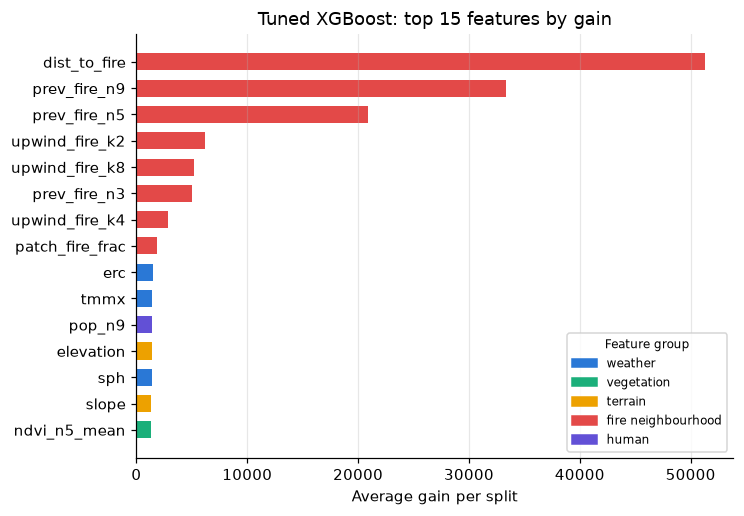

dist_to_fire       0.338
prev_fire_n9       0.220
prev_fire_n5       0.138
upwind_fire_k2     0.041
upwind_fire_k8     0.034
prev_fire_n3       0.033
upwind_fire_k4     0.019
patch_fire_frac    0.012
erc                0.010
tmmx               0.009
pop_n9             0.009
elevation          0.009
sph                0.009
slope              0.009
ndvi_n5_mean       0.009
dtype: float64

In [11]:
GROUP_OF = {f: g for g, feats in FEATURE_GROUPS.items() for f in feats}
GROUP_COLORS = dict(zip(FEATURE_GROUPS, ["#2a78d6", "#1baf7a", "#eda100", "#e34948", "#6250d6"]))

gain = pd.Series(model.get_booster().get_score(importance_type="gain")).sort_values(ascending=False)
top = gain.head(15)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index[::-1], top.values[::-1], color=[GROUP_COLORS[GROUP_OF[f]] for f in top.index[::-1]], height=0.65)
ax.set(xlabel="Average gain per split", title="Tuned XGBoost: top 15 features by gain")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=c, label=g.replace("_", " ")) for g, c in GROUP_COLORS.items()],
          loc="lower right", fontsize=8, title="Feature group", title_fontsize=8)
fig.savefig(FIGS / "eval_gain_importance.png")
plt.show()
(gain / gain.sum()).round(3).head(15)

### 4b · SHAP values

SHAP splits each prediction (in log-odds) into one additive contribution per feature; positive = pushes toward fire.
`TreeExplainer` computes them exactly for tree models.
Sample: 20,000 labelled test pixels, 10,000 fire (drawn from the 84,331 fire pixels) and 10,000 no-fire, seed 0.
Fire pixels are over-represented on purpose so both classes are visible; the sample is for explaining, not for scoring.

(20000, 35) (20000, 35)


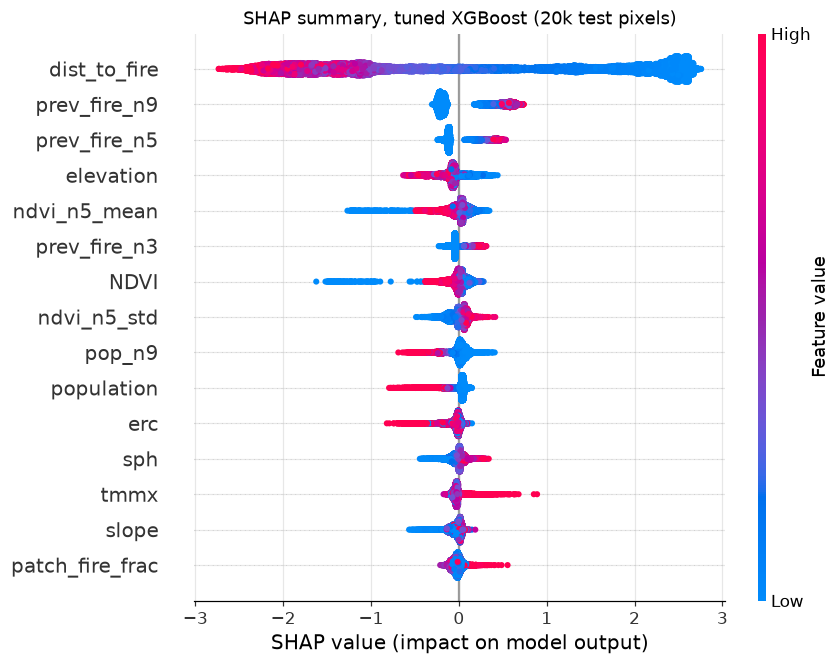

In [12]:
labelled_px = test[test["label"] != -1]
fire_px = labelled_px[labelled_px["label"] == 1]
n_fire = min(len(fire_px), 10_000)
sample = pd.concat([
    fire_px.sample(n_fire, random_state=SEED),
    labelled_px[labelled_px["label"] == 0].sample(20_000 - n_fire, random_state=SEED),
])
X_shap = sample[ALL_FEATURES]

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_shap)     # (20000, n_features), log-odds units
print(X_shap.shape, shap_values.shape)

shap.summary_plot(shap_values, X_shap, max_display=15, show=False, plot_size=(8, 6))
plt.title("SHAP summary, tuned XGBoost (20k test pixels)")
plt.savefig(FIGS / "eval_shap_summary.png")
plt.show()

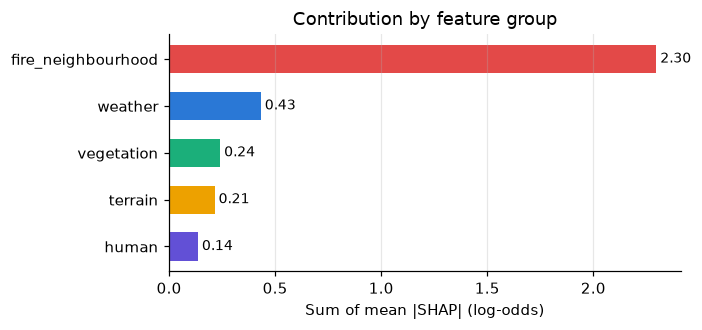

fire_neighbourhood    2.297
weather               0.432
vegetation            0.241
terrain               0.214
human                 0.136
dtype: float32

In [13]:
# Importance by feature group: sum of mean |SHAP| over the features in each group.
mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=ALL_FEATURES)
by_group = mean_abs.groupby(GROUP_OF).sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(by_group.index[::-1], by_group.values[::-1], color=[GROUP_COLORS[g] for g in by_group.index[::-1]], height=0.6)
for k, v in enumerate(by_group.values[::-1]):
    ax.text(v, k, f" {v:.2f}", va="center", fontsize=9)
ax.set(xlabel="Sum of mean |SHAP| (log-odds)", title="Contribution by feature group")
ax.grid(axis="y", visible=False)
fig.savefig(FIGS / "eval_shap_groups.png")
plt.show()
by_group.round(3)

### 4c · Physical plausibility check

Two questions:
1. **Does the model push risk downwind?** For every day-t fire pixel we step 1-5 pixels downwind (where the wind blows **to**)
   and 1-5 pixels upwind, keep the stepped-to pixels that are not burning on day t, and compare the mean predicted probability.
   The true next-day fire rate in the same pixels tells us whether the data itself shows downwind spread.
   Geometry: `th` is where the wind comes **from**, degrees clockwise from north; patches are north-up, so one pixel
   downwind is row + cos(th), column − sin(th) (rows grow southward).
2. **Do the SHAP signs make physical sense?** Spearman correlation between a feature's value and its SHAP value:
   positive = higher value pushes toward fire.

In [14]:
def wind_sides(prev, th, vs, labels, probs=None, wind_bins=(0, 99)):
    """Compare pixels 1-5 px downwind vs upwind of day-t fire.

    prev, th, vs, labels: (N, 64, 64) maps; probs: dict name -> (N, 64, 64) probabilities (optional).
    Only target pixels that are NOT burning on day t are used. One row per (wind band, distance, side).
    """
    fire = prev == 1
    pf, rf, cf = np.nonzero(fire)                          # every day-t fire pixel
    rad = np.deg2rad(th[pf, rf, cf])
    step_row, step_col = np.cos(rad), -np.sin(rad)          # one pixel downwind (rows grow southward)
    speed = vs[pf, rf, cf]
    rows = []
    for lo, hi in zip(wind_bins[:-1], wind_bins[1:]):
        m = (speed >= lo) & (speed < hi)                    # fire pixels in this wind-speed band
        for d in range(1, 6):
            sides = {}
            for side, sign in (("downwind", 1), ("upwind", -1)):
                r = np.rint(rf[m] + sign * d * step_row[m]).astype(int)
                c = np.rint(cf[m] + sign * d * step_col[m]).astype(int)
                inside = (r >= 0) & (r < 64) & (c >= 0) & (c < 64)
                flat = np.unique(np.ravel_multi_index((pf[m][inside], r[inside], c[inside]), labels.shape))
                sides[side] = flat[~fire.flat[flat]]        # drop pixels already burning on day t
            both = np.intersect1d(sides["downwind"], sides["upwind"])  # downwind of one fire, upwind of another
            for side, idx in sides.items():
                idx = np.setdiff1d(idx, both)
                y = labels.flat[idx]
                row = {"wind_m/s": f"{lo}-{hi}", "distance_px": d, "side": side, "pixels": len(idx),
                       "true_fire_rate": (y[y != -1] == 1).mean()}
                for name, p in (probs or {}).items():
                    row[name] = p.flat[idx].mean()
                rows.append(row)
    return pd.DataFrame(rows)


p_raw = load_preds("xgb_raw")[1]
wind_check = wind_sides(prev_map, th_map, vs_map, y_map, {"xgb_tuned": p_xgb, "xgb_raw": p_raw})
wind_check.round(3)

,wind_m/s,distance_px,side,pixels,true_fire_rate,xgb_tuned,xgb_raw
0,0-99,1,downwind,20929,0.206,0.938,0.427
1,0-99,1,upwind,20814,0.193,0.938,0.439
2,0-99,2,downwind,30900,0.163,0.921,0.427
3,0-99,2,upwind,31208,0.156,0.920,0.442
4,0-99,3,downwind,38065,0.128,0.897,0.429
5,0-99,3,upwind,38124,0.133,0.894,0.448
6,0-99,4,downwind,42615,0.106,0.867,0.427
7,0-99,4,upwind,42316,0.116,0.862,0.448
8,0-99,5,downwind,45856,0.090,0.834,0.428
9,0-99,5,upwind,45469,0.101,0.828,0.447


In [15]:
# Does the DATA show downwind spread? Same check on the much larger train split, split by wind speed
# (wind direction only matters when there is wind). Only the 3 channels we need are kept in memory.
X_tr, y_tr = load_split("train")
prev_tr, th_tr = X_tr[:, CHANNELS.index("PrevFireMask")], X_tr[:, CHANNELS.index("th")] % 360
vs_tr = np.clip(X_tr[:, CHANNELS.index("vs")], 0, None)
del X_tr
BANDS = (0, 3, 5, 8, 99)
by_wind = pd.concat([
    wind_sides(prev_tr, th_tr, vs_tr, y_tr, wind_bins=BANDS).assign(split="train"),
    wind_sides(prev_map, th_map, vs_map, y_map, wind_bins=BANDS).assign(split="test"),
])
del prev_tr, th_tr, vs_tr, y_tr
# Ratio > 1: more next-day fire downwind than upwind (what physics predicts).
ratio = by_wind.pivot_table(index=["split", "wind_m/s", "distance_px"], columns="side", values="true_fire_rate")
ratio["down/up"] = ratio["downwind"] / ratio["upwind"]
ratio.loc[(slice(None), slice(None), [2, 5]), :].round(3)

side                        downwind  upwind  down/up
split wind_m/s distance_px                           
test  0-3      2               0.172   0.137    1.252
               5               0.088   0.075    1.180
      3-5      2               0.161   0.166    0.969
               5               0.095   0.114    0.835
      5-8      2               0.139   0.174    0.803
               5               0.056   0.128    0.434
      8-99     2               0.000   0.000      NaN
               5               0.000   0.079    0.000
train 0-3      2               0.193   0.178    1.084
               5               0.122   0.101    1.209
      3-5      2               0.183   0.182    1.011
               5               0.124   0.114    1.091
      5-8      2               0.166   0.189    0.875
               5               0.118   0.130    0.904
      8-99     2               0.061   0.147    0.413
               5               0.040   0.109    0.363

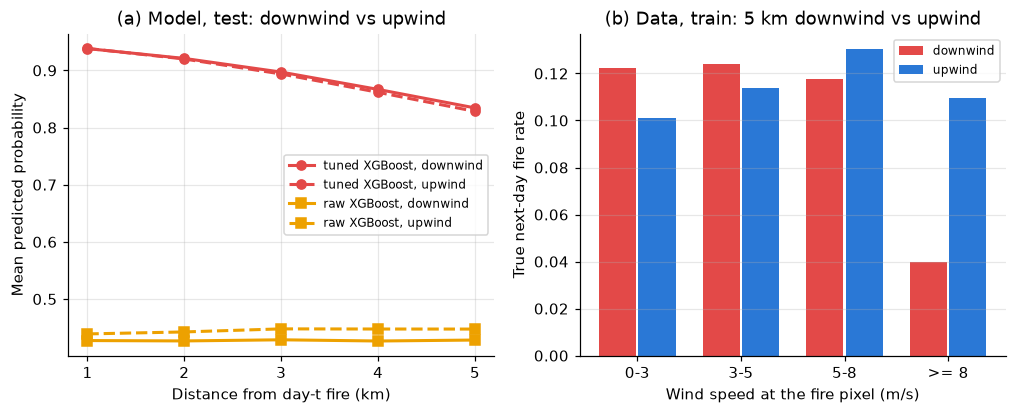

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
# (a) model: mean probability downwind vs upwind, all wind speeds, test split
for name, color, mk in (("xgb_tuned", "#e34948", "o"), ("xgb_raw", "#eda100", "s")):
    for side, ls in (("downwind", "-"), ("upwind", "--")):
        s = wind_check[wind_check["side"] == side]
        axes[0].plot(s["distance_px"], s[name], ls, marker=mk, lw=2, color=color,
                     label=f"{'tuned' if name == 'xgb_tuned' else 'raw'} XGBoost, {side}")
axes[0].set(xlabel="Distance from day-t fire (km)", ylabel="Mean predicted probability", xticks=range(1, 6),
            title="(a) Model, test: downwind vs upwind")
axes[0].legend(fontsize=8)
# (b) data: true fire rate 5 km downwind vs upwind, by wind speed, train split
s = by_wind[(by_wind["split"] == "train") & (by_wind["distance_px"] == 5)]
x = np.arange(len(BANDS) - 1)
for k, (side, color) in enumerate((("downwind", "#e34948"), ("upwind", "#2a78d6"))):
    v = s[s["side"] == side]["true_fire_rate"].to_numpy()
    axes[1].bar(x + (k - 0.5) * 0.38, v, width=0.36, color=color, label=side)
axes[1].set_xticks(x, [f"{a}-{b}" if b < 99 else f">= {a}" for a, b in zip(BANDS[:-1], BANDS[1:])])
axes[1].set(xlabel="Wind speed at the fire pixel (m/s)", ylabel="True next-day fire rate",
            title="(b) Data, train: 5 km downwind vs upwind")
axes[1].grid(axis="x", visible=False)
axes[1].legend(fontsize=8)
fig.savefig(FIGS / "eval_downwind_check.png")
plt.show()

In [17]:
CHECK = ["upwind_fire_k2", "upwind_fire_k4", "upwind_fire_k8", "fire_wind_alignment",
         "dist_to_fire", "prev_fire_n3", "min_rel_humidity", "vpd", "erc", "vs", "NDVI", "slope"]
sign_table = pd.DataFrame({
    "mean_abs_shap": mean_abs[CHECK],
    "spearman(value, shap)": [X_shap[f].corr(pd.Series(shap_values[:, ALL_FEATURES.index(f)], index=X_shap.index),
                                             method="spearman") for f in CHECK],
})
sign_table.round(3)

,mean_abs_shap,"spearman(value, shap)"
upwind_fire_k2,0.012,0.691
upwind_fire_k4,0.007,0.612
upwind_fire_k8,0.005,0.467
fire_wind_alignment,0.008,-0.654
dist_to_fire,1.609,-0.970
prev_fire_n3,0.085,0.752
min_rel_humidity,0.021,-0.633
vpd,0.039,0.745
erc,0.057,-0.315
vs,0.031,0.785


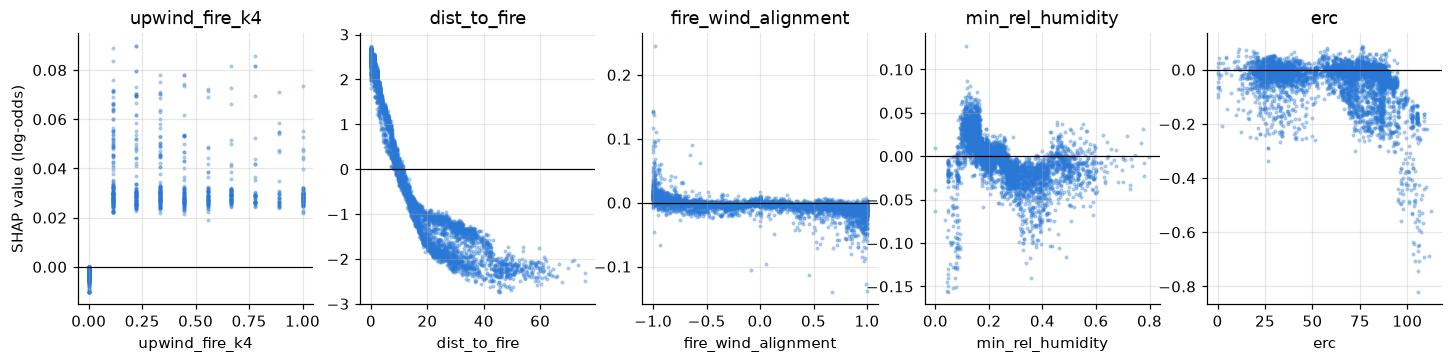

In [18]:
# Dependence plots: how the SHAP value of a feature changes with its value (5k points per panel).
show = ["upwind_fire_k4", "dist_to_fire", "fire_wind_alignment", "min_rel_humidity", "erc"]
pts = np.random.default_rng(SEED).choice(len(X_shap), 5000, replace=False)
fig, axes = plt.subplots(1, len(show), figsize=(16, 3.2))
for ax, f in zip(axes, show):
    ax.scatter(X_shap[f].to_numpy()[pts], shap_values[pts, ALL_FEATURES.index(f)], s=3, alpha=0.3, color="#2a78d6")
    ax.axhline(0, color="black", lw=0.8)
    ax.set(xlabel=f, title=f)
axes[0].set_ylabel("SHAP value (log-odds)")
fig.savefig(FIGS / "eval_shap_dependence.png")
plt.show()

**Interpretation**

*What the model relies on.* The refitted model is identical to the evaluated one (same test PR AUC, zero difference in
probabilities). The 8 fire-neighbourhood features in the gain top 15 hold ≈84% of total gain:
`dist_to_fire` 34%, `prev_fire_n9` 22%, `prev_fire_n5` 14%. SHAP agrees: the fire-neighbourhood group contributes
2.30 log-odds on average against 0.43 for all weather features together (≈69% of the total).
`dist_to_fire` alone moves a prediction from about +2.5 (at the fire) to −2.5 (40+ km away), crossing zero near 10 km.

*Signs that agree with fire physics.*
- Closer to fire and more fire nearby → higher risk (`dist_to_fire` ρ = −0.97, `prev_fire_n3` +0.75).
- Low NDVI (bare ground, water, no fuel) → strongly lower risk; flat terrain (low slope) → lower risk.
- Hotter, drier air → higher risk: `tmmx` +, `vpd` + (ρ = +0.75), `min_rel_humidity` − (ρ = −0.63) over its main range 0.1-0.5.
- Higher wind speed → higher risk (`vs` ρ = +0.79). Dense population → lower risk (built-up land, faster suppression).
- Fire 2/4/8 px upwind always raises the prediction (ρ = +0.69 / +0.61 / +0.47), but only a little
  (mean |SHAP| 0.005-0.012 log-odds vs 1.61 for `dist_to_fire`; 0.02-0.09 for `upwind_fire_k4` in the dependence plot).

*Signs that do not.* High `erc` (dry fuel) lowers risk, most strongly above ≈95, and higher specific humidity raises it.
Both are regional or seasonal values (4 km grid, constant over most of a patch), so the model most likely uses them as a
proxy for *where/when* a fire is, not as a causal driver. `min_rel_humidity` carries the physically correct humidity effect.
`fire_wind_alignment` gets almost zero SHAP everywhere: the model ignores it.

*Does the model push risk downwind?* **No.** In panel (a) the mean probability 1-5 km downwind and upwind of day-t fire
differs by less than 0.006 at every distance. The raw-channel XGBoost is flat at ≈0.43 because it does not know where the fire is.

*Does the data show downwind spread?* Only weakly, and not consistently (panel b, train split):
with wind below 5 m/s next-day fire is 9-21% more frequent 5 km downwind than upwind, as expected;
with wind of 5 m/s or more the pattern **reverses**: at ≥ 8 m/s fire is 2.7× more frequent on the "upwind" side
(0.109 vs 0.040). The test split shows the same reversal (5-8 m/s: ratio 0.43).
Strong wind is exactly where the direction should matter most, so this needs checking. Two possible causes:
(i) the direction convention used in `src/features.py` (`th` = wind blows *from*, patches north-up) is flipped for this export;
(ii) a physical confounder, e.g. strong offshore winds pushing fire toward the coast or unburnable land.
Either way the upwind features carry mixed signal, which explains why the model barely uses them.
This is flagged to the feature-engineering owner and is a motivation for Phase 2: a CNN sees the wind field as an
image and can learn its relation to the fire front without a hand-coded convention.

## 5 · Error analysis (tuned XGBoost at the eval-chosen threshold)

For each test patch, count false-positive pixels (predicted fire, no fire on day t+1) and false-negative pixels
(fire on day t+1, not predicted); -1 pixels are ignored. The 5 worst patches of each kind are plotted as in Task 3.

test totals: TP 42,546  FP 123,019  FN 41,785


worst FP patches: [285, 475, 1339, 656, 368] | worst FN patches: [173, 1264, 1199, 513, 106]
share of all FP in the 5 worst patches: 0.029
share of all FN in the 5 worst patches: 0.037


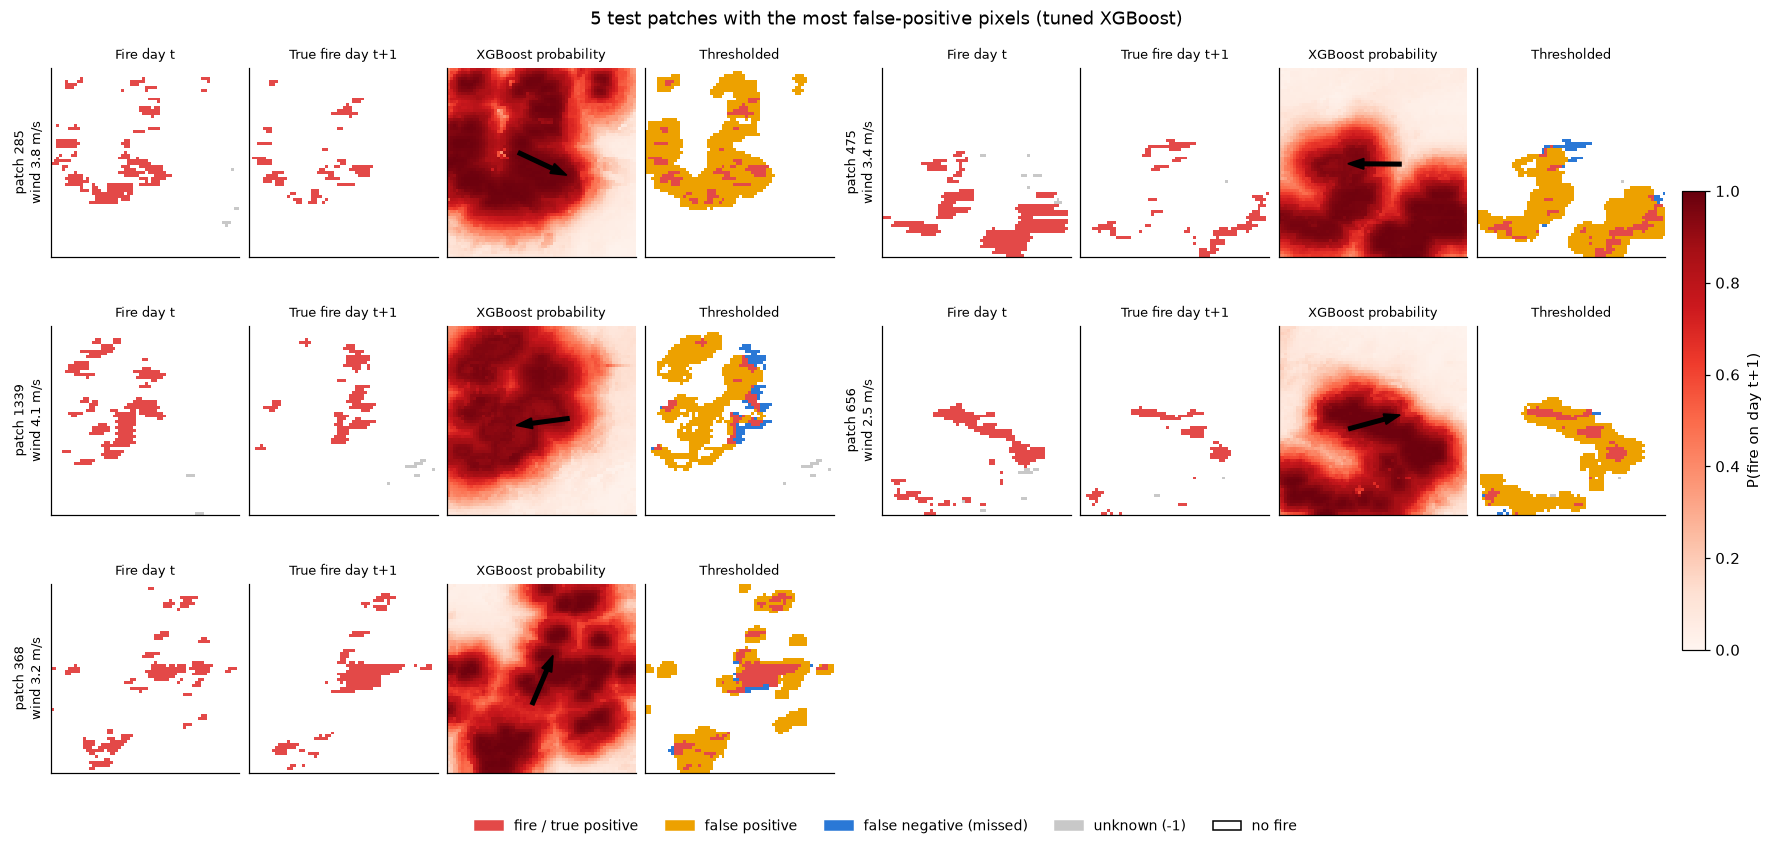

,fire_t,fire_t+1,TP,FP,FN,unknown_t+1,wind_m/s
patch,,,,,,,
285,316,162,162,920,0,0,3.8
475,468,193,145,818,48,1,3.4
1339,334,189,89,678,100,13,4.1
656,255,136,128,632,8,3,2.5
368,277,259,237,580,22,0,3.2


In [19]:
lab = y_map != -1
tp = ((y_map == 1) & pred_xgb).sum(axis=(1, 2))
fp = ((y_map == 0) & pred_xgb).sum(axis=(1, 2))
fn = ((y_map == 1) & ~pred_xgb).sum(axis=(1, 2))
print(f"test totals: TP {tp.sum():,}  FP {fp.sum():,}  FN {fn.sum():,}")

fire_t_px = (prev_map == 1).sum(axis=(1, 2))
fire_t1_px = (y_map == 1).sum(axis=(1, 2))


from numpy.lib.stride_tricks import sliding_window_view


def same_place(a, b, k=16):
    """True if any of 9 k x k elevation blocks of patch a appears exactly (shifted) inside patch b.

    Elevation is static, so two crops of the same place share it, just shifted. Checking 9 blocks spread over
    the patch catches crops that overlap only partly. A flat block (e.g. sea) is skipped: it could match anywhere.
    """
    windows = sliding_window_view(elev_map[b], (k, k))       # every k x k window of patch b
    for r0 in (0, 24, 48):
        for c0 in (0, 24, 48):
            block = elev_map[a, r0:r0 + k, c0:c0 + k]
            if block.std() > 0 and (windows == block).all(axis=(2, 3)).any():
                return True
    return False


def distinct_fires(order, k=5):
    """First k patches in `order` that show different places (so different fires).

    The dataset contains several overlapping crops of the same large fire; without this check the
    5 worst false-negative patches were 5 crops of one fire.
    """
    keep = []
    for i in order:
        if not any(same_place(i, j) or same_place(j, i) for j in keep):
            keep.append(i)
        if len(keep) == k:
            break
    return np.array(keep)


worst_fp = distinct_fires(np.argsort(-fp, kind="stable"))
worst_fn = distinct_fires(np.argsort(-fn, kind="stable"))
print("worst FP patches:", worst_fp.tolist(), "| worst FN patches:", worst_fn.tolist())
print("share of all FP in the 5 worst patches:", round(fp[worst_fp].sum() / fp.sum(), 3))
print("share of all FN in the 5 worst patches:", round(fn[worst_fn].sum() / fn.sum(), 3))

plot_patches(worst_fp, FIGS / "eval_worst_fp.png", "5 test patches with the most false-positive pixels (tuned XGBoost)")
patch_stats(worst_fp)

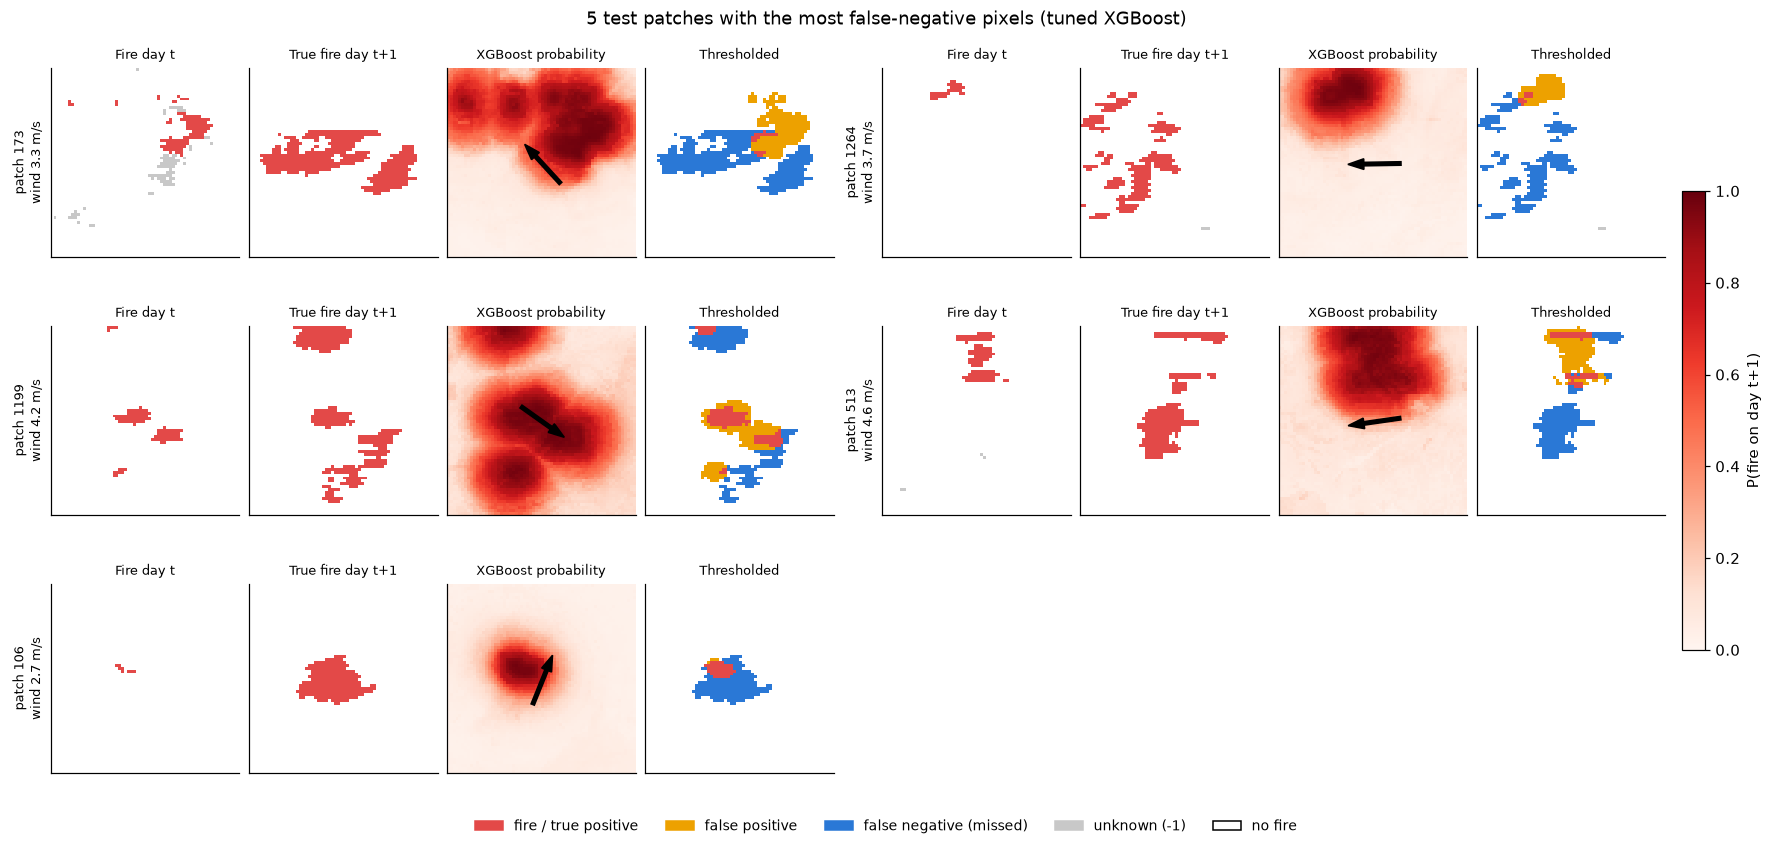

,fire_t,fire_t+1,TP,FP,FN,unknown_t+1,wind_m/s
patch,,,,,,,
173,116,515,20,237,495,0,3.3
1264,35,333,12,115,321,3,3.7
1199,104,406,138,194,268,0,4.2
513,121,324,58,171,266,0,4.6
106,8,260,48,4,212,0,2.7


In [20]:
plot_patches(worst_fn, FIGS / "eval_worst_fn.png", "5 test patches with the most false-negative pixels (tuned XGBoost)")
patch_stats(worst_fn)

In [21]:
# Split-wide patterns behind the worst cases.
dist = test["dist_to_fire"].to_numpy().reshape(-1, 64, 64)   # km to nearest day-t fire (90.5 = no fire in patch)
fn_px, fp_px = (y_map == 1) & ~pred_xgb, (y_map == 0) & pred_xgb
no_fire_t = ~(prev_map == 1).any(axis=(1, 2))                  # patches with no day-t fire at all
shrinking = fire_t1_px < fire_t_px                            # fire covers fewer pixels on day t+1

summary = pd.Series({
    "FN pixels > 5 km from any day-t fire": (dist[fn_px] > 5).mean(),
    "test patches with no day-t fire (count)": no_fire_t.sum(),
    "TP pixels > 5 km from any day-t fire": (dist[(y_map == 1) & pred_xgb] > 5).mean(),
    "FP pixels within 2 km of day-t fire": (dist[fp_px] <= 2).mean(),
    "FP pixels in shrinking-fire patches": shrinking[np.nonzero(fp_px)[0]].mean(),
    "patches that are shrinking (of patches with day-t fire)": shrinking[~no_fire_t].mean(),
    "day-t fire pixels still burning on day t+1": (y_map[prev_map == 1] == 1).mean(),
})
summary.round(3)

FN pixels > 5 km from any day-t fire                       0.615
test patches with no day-t fire (count)                    0.000
TP pixels > 5 km from any day-t fire                       0.000
FP pixels within 2 km of day-t fire                        0.931
FP pixels in shrinking-fire patches                        0.536
patches that are shrinking (of patches with day-t fire)    0.384
day-t fire pixels still burning on day t+1                 0.353
dtype: float64

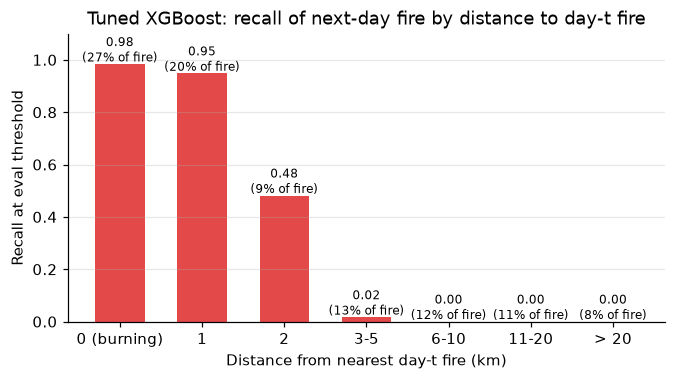

,fire pixels,share of all fire,recall
band,,,
0 (burning),23003,0.273,0.984
1,16916,0.201,0.948
2,7675,0.091,0.481
3-5,11024,0.131,0.017
6-10,10041,0.119,0.000
11-20,8968,0.106,0.000
> 20,6704,0.079,0.000


In [22]:
# Recall by distance to the nearest day-t fire: how fast does the model's skill fall off away from the front?
bins = [0, 0.5, 1.5, 2.5, 5, 10, 20, 91]
names = ["0 (burning)", "1", "2", "3-5", "6-10", "11-20", "> 20"]
fire_px_mask = y_map == 1
band = pd.cut(dist[fire_px_mask], bins, labels=names, include_lowest=True)
by_dist = pd.DataFrame({"band": band, "found": pred_xgb[fire_px_mask]}).groupby("band", observed=False)["found"]
recall_by_dist = pd.DataFrame({"fire pixels": by_dist.size(), "share of all fire": by_dist.size() / fire_px_mask.sum(),
                               "recall": by_dist.mean()})

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(recall_by_dist.index.astype(str), recall_by_dist["recall"], color="#e34948", width=0.6)
for k, (r, s) in enumerate(zip(recall_by_dist["recall"], recall_by_dist["share of all fire"])):
    ax.text(k, r + 0.01, f"{r:.2f}\n({s:.0%} of fire)", ha="center", fontsize=8)
ax.set(xlabel="Distance from nearest day-t fire (km)", ylabel="Recall at eval threshold", ylim=(0, 1.1),
       title="Tuned XGBoost: recall of next-day fire by distance to day-t fire")
ax.grid(axis="x", visible=False)
fig.savefig(FIGS / "eval_recall_by_distance.png")
plt.show()
recall_by_dist.round(3)

**Error patterns**

Totals at the eval threshold: 42.5k true positives, 123.0k false positives and 41.8k false negatives
(precision 0.26, recall 0.50).

*False positives: the model over-predicts around large, fragmented fires that are dying down.*
The 5 worst patches (285, 475, 1339, 656, 368) all hold large, scattered day-t fires (255-468 pixels), and the model draws a
≈2 km halo of high probability around every burning pixel. In 4 of the 5 the fire shrinks the next day
(316→162, 468→193, 334→189, 255→136 pixels). Split-wide, only 35% of day-t fire pixels still burn on day t+1;
93% of all false positives lie within 2 km of day-t fire, and 54% come from shrinking patches although only 38% of patches shrink.
The features cannot say which fires will die down: there is no burn-scar (fuel already consumed), containment or
next-day weather information. Detection noise in MODIS (smoke, satellite timing) adds to it.

*False negatives: the model misses long jumps and explosive growth.*
- Long-range spread or new fire 10-40 km from the day-t fire: patch 173 (the fire runs ≈30 km west),
  1264 and 513 (new fire 15-40 km south of the day-t fire), 1199 (new clusters south-east).
  In 173 part of the day-t fire is hidden under cloud (grey), so the true front was partly invisible to the model.
- Explosive growth of a small fire: patch 106 goes from 8 to 260 burning pixels; the predicted halo covers only the centre.
- Split-wide, 61.5% of missed fire pixels are more than 5 km from any day-t fire, and the model finds **no** fire pixel
  beyond 5 km. 43% of next-day fire lies 3 km or more from the day-t fire, and recall there is below 1%
  (98% on already-burning pixels, 95% at 1 km, 48% at 2 km).

*Data caveat.* The test split holds 40 exact duplicate patches and several overlapping crops of the same large fire
(the first version of this analysis picked 5 crops of one fire as the "5 worst"). Metrics are therefore weighted toward
large fires; an event-level evaluation would be fairer and is suggested for Phase 2.

*What this means for Phase 2.* A per-pixel model with neighbourhood summaries learns a fixed-radius halo.
The errors are about fire-front shape, long-range spread and whether a fire is growing or dying,
which is spatial context a CNN / U-Net sees directly.